# Real or Fake Image Recognition Task Using a Convolutional Neural Network

**APOAI2025 Mock Competition Question 2**

For this question, I built a model that receives a colored image and predicts whether it is **real (0)** or **generated (1)**. This notebook includes the complete code and the actual results from running it using `CIFAR10's "real"` images and a `diffusion model's "fake"` images.

# 1. The Plan

As what the problem has state, the dataset supplied images on the two folders are 32 pixels wide and 32 pixels high wherein each pixel has red, green, and blue values. I used a **convolutional neural network (CNN)** which is a suitable model for this machine learning task as it learns small image patterns and combines them to make a decision. I used a small model to balance the image-classification task wherein the model produces only `two scores` in which the larger score determines its actual prediction.

# 2. Setup of the model

| Setting | Value |
| --- | ---: |
| Maximum development epochs | 40 |
| Batch size | 64 |
| Starting learning rate | 0.001 |
| Weight decay | 0.0001 |
| Seed | 42 |
| CPU threads | 4 |

I use these settings to train the development model, while checking its performance on the validation images after each epoch so that I can select a training length before evaluating the holdout. The maximum of 40 epochs is the development search limit, while the selected epoch determines how long I train the later evaluation and final models.

The initial settings were informed by an [LLM suggestion](https://chatgpt.com/share/6acf7100-ab18-83ec-8341-f8193559edca) and I assess their usefulness through the measured validation and holdout results.

In [1]:
from pathlib import Path
from time import perf_counter

NOTEBOOK_START = perf_counter()


def find_question_folder(name, marker):
    cwd = Path.cwd().resolve()

    for base in (cwd, *cwd.parents):
        candidates = [base] if base.name == name else []
        candidates += [base / name, base / 'ICAIC_Outputs' / name]

        for folder in candidates:
            if (folder / marker).exists():
                return folder.resolve()

    if (cwd / marker).exists():
        return cwd

    raise FileNotFoundError(
        f'Cannot find {name}/{marker} from {cwd}. '
        'Keep the supplied data inside its question folder.'
    )

In [2]:
import math
import random
from types import SimpleNamespace
import matplotlib.pyplot as plt
import torch
from PIL import Image
from torch import nn
from IPython.display import Markdown, display

PART_FOLDER = find_question_folder('Question2', 'train_v1')
DATA_DIR = PART_FOLDER / 'train_v1'
OUTPUT_DIR = PART_FOLDER

settings = SimpleNamespace(epochs=40, batch_size=64, learning_rate=0.001, seed=42, threads=4)
torch.set_num_threads(settings.threads)
torch.use_deterministic_algorithms(True)
print('Image folder:', DATA_DIR)
print('Output folder:', OUTPUT_DIR)

Image folder: /Users/davidfrancisco/Documents/ICAIC_Outputs/Question2/train_v1
Output folder: /Users/davidfrancisco/Documents/ICAIC_Outputs/Question2


## 3. Read and prepare the images

I loaded the supplied 32 × 32 images and assigned label **0** to real images in `cifar` and label **1** to generated images in `uvit`. Then, I converted the images to RGB and divided pixel values by 255 to scale them from **0–255** to **0–1** so its smaller and consistenly scaled to make training easier to manage.

The image tensor has shape `(10000, 3, 32, 32)`: 10,000 images, three colour channels, and 32 × 32 pixels. Training processes up to 64 images per batch.

In [3]:
def read_data(folder):
    images = []
    labels = []
    for label, name in enumerate(('cifar', 'uvit')):
        for path in sorted((folder / name).glob('*.png')):
            with Image.open(path) as original:
                image = original.convert('RGB')
                pixels = torch.frombuffer(bytearray(image.tobytes()), dtype=torch.uint8)
                pixels = pixels.reshape(32, 32, 3).permute(2, 0, 1)
                images.append(pixels.float() / 255.0)
            labels.append(label)
    return torch.stack(images), torch.tensor(labels, dtype=torch.long)

images, labels = read_data(DATA_DIR)
counts = torch.bincount(labels, minlength=2)
print(f'Labeled images: {len(images):,}')
print(f'Real: {counts[0].item():,}; generated: {counts[1].item():,}')
print('Image shape:', tuple(images.shape))

Labeled images: 10,000
Real: 5,000; generated: 5,000
Image shape: (10000, 3, 32, 32)


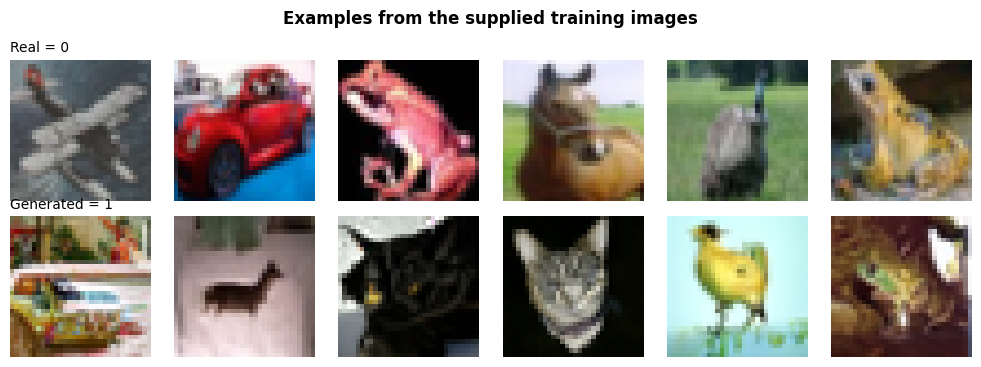

In [4]:
fig, axes = plt.subplots(2, 6, figsize=(10, 3.7))
for label, name in enumerate(('Real = 0', 'Generated = 1')):
    indices = (labels == label).nonzero().flatten()[:6]
    for column, index in enumerate(indices.tolist()):
        axes[label, column].imshow(images[index].permute(1, 2, 0))
        axes[label, column].set_axis_off()
        if column == 0:
            axes[label, column].set_title(name, fontsize=10, loc='left')
fig.suptitle('Examples from the supplied training images', fontweight='bold')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / '01_image_examples.png', bbox_inches='tight')
plt.show()
plt.close(fig)

# 4. Separate images for choosing and checking

We know that a **label** is the known answer and based from the problem's instructions:

10,000 labeled images are splitted into two:
- 8,000 development images = 6,400 to learn the weights and 1,600 to choose the number of training passes
- 2,000 is kept for the final local check

The split then chooses about 20% of the real images and 20% of the generated images separately which preserves the real/generated mix using the given seed I setup from the start.

In [5]:
def split_data(indices, labels, seed):
    rng = random.Random(seed)
    answers = labels.tolist()
    training = []
    holdout = []
    for label in (0, 1):
        group = [index for index in indices if answers[index] == label]
        rng.shuffle(group)
        count = round(0.2 * len(group))
        holdout.extend(group[:count])
        training.extend(group[count:])
    rng.shuffle(training)
    rng.shuffle(holdout)
    return (torch.tensor(training), torch.tensor(holdout))

development, holdout = split_data(list(range(len(labels))), labels, settings.seed)
training, validation = split_data(development.tolist(), labels, settings.seed + 1)
print(f'Learn weights: {len(training):,}')
print(f'Choose epoch count: {len(validation):,}')
print(f'Final local check: {len(holdout):,}')

Learn weights: 6,400
Choose epoch count: 1,600
Final local check: 2,000


# 5. Build the Convolutional Neural Network

1. Input are the 3 colors (RGB) which has a shape of `3 x 32 x 32`
2. It gets forwarded to Convolution 1 + ReLU and learns 32 small-pattern responses while replacing negative responses with 0 to add non-linearity. It's shape is now `32 x 32 x 32`
3. Max Pooled the response for the first time which gets the largest response in each 2 x 2 area which now updates the shape to `32 x 16 x 16`
4. It gets forwarded to Convolution 2 + ReLU which combines the responses into 64 furger patters which gives a shape of `64 x 16 x 16`
5. Max pooled the response again to reduce the grid again to its half making it a shape of `64 x 8 x 8`
6. Flatten the grid values into one row which giveds a total of `4,096` values
7. I then make it linear to calculate one final score for each answer.

In [6]:
class MyModel(nn.Module):

    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, 3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(2)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(2)
        self.fc1 = nn.Linear(64 * 8 * 8, 2)

    def forward(self, x):
        x = self.conv1(x)
        x = self.relu1(x)
        x = self.pool1(x)
        x = self.conv2(x)
        x = self.relu2(x)
        x = self.pool2(x)
        x = x.flatten(1)
        x = self.fc1(x)
        return x

example_model = MyModel()
print(example_model)

MyModel(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=4096, out_features=2, bias=True)
)


# 6. Train and choose the stopping epoch

Now, I trained the model using the 6,400 training images in batches and for each batch, the model predicts real or generated while cross-entropy loss compares its scores with the correct labels. Adam then adjusts the weights to reduce the loss.

I then shuffle the images each epoch and randomly mirror some training images horizontally in which the learning rate gradually decreases so the weight updates become smaller later in training. After each epoch, I check accuracy on the 1,600 validation images without changing the weights. I also choose the epoch count with the highest validation accuracy. The remaining 2,000 holdout images are then kept for the later check and then the next stage trains a fresh model for this selected number of epochs.


In [7]:
@torch.no_grad()
def evaluate(model, images, labels, batch_size):
    model.eval()
    total_loss = 0.0
    correct = 0
    confusion = torch.zeros(2, 2, dtype=torch.long)
    for start in range(0, len(images), batch_size):
        batch_images = images[start:start + batch_size]
        batch_labels = labels[start:start + batch_size]
        scores = model(batch_images)
        loss = nn.CrossEntropyLoss()(scores, batch_labels)
        predictions = scores.argmax(dim=1)
        correct += (predictions == batch_labels).sum().item()
        total_loss += loss.item() * len(batch_labels)
        for actual in (0, 1):
            for predicted in (0, 1):
                confusion[actual, predicted] += ((batch_labels == actual) & (predictions == predicted)).sum()
    return {'accuracy': correct / len(labels), 'cross_entropy': total_loss / len(labels), 'correct': correct, 'total': len(labels), 'confusion_matrix': confusion.tolist()}

def fit(images, labels, epochs, args, validation=None):
    torch.manual_seed(args.seed)
    model = MyModel()
    optimizer = torch.optim.Adam(model.parameters(), lr=args.learning_rate, weight_decay=0.0001)
    loss_function = nn.CrossEntropyLoss()
    generator = torch.Generator().manual_seed(args.seed + 1000)
    best_key = None
    best_epoch = epochs
    best_metrics = None
    history = []
    for epoch in range(1, epochs + 1):
        model.train()
        learning_rate = args.learning_rate * (0.1 + 0.9 * (1 + math.cos(math.pi * (epoch - 1) / args.epochs)) / 2)
        optimizer.param_groups[0]['lr'] = learning_rate
        order = torch.randperm(len(images), generator=generator)
        total_loss = 0.0
        for start in range(0, len(images), args.batch_size):
            batch = order[start:start + args.batch_size]
            batch_images = images[batch]
            flip = torch.rand(len(batch), generator=generator) < 0.5
            batch_images[flip] = batch_images[flip].flip(3)
            optimizer.zero_grad(set_to_none=True)
            scores = model(batch_images)
            loss = loss_function(scores, labels[batch])
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(batch)
        record = {'epoch': epoch, 'training_loss': total_loss / len(images)}
        if validation is not None:
            metrics = evaluate(model, *validation, args.batch_size)
            record['validation'] = metrics
            key = (metrics['accuracy'], -metrics['cross_entropy'])
            if best_key is None or key > best_key:
                best_key = key
                best_epoch = epoch
                best_metrics = metrics
        history.append(record)
        if epoch == 1 or epoch % 5 == 0 or epoch == epochs:
            message = f"Epoch {epoch}/{epochs}: training loss={record['training_loss']:.6f}"
            if validation is not None:
                message += f"; validation accuracy={metrics['accuracy']:.2%}"
            print(message, flush=True)
    model.eval()
    return (model, best_epoch, best_metrics, history)


In [8]:
print('Choosing the epoch count using only the validation group:')
_, chosen_epoch, chosen_metrics, history = fit(
    images[training], labels[training], settings.epochs, settings,
    validation=(images[validation], labels[validation]),
)
print(f'Selected epoch: {chosen_epoch}')
print(f'Validation accuracy: {chosen_metrics["accuracy"]:.2%}')

Choosing the epoch count using only the validation group:
Epoch 1/40: training loss=0.627543; validation accuracy=70.06%
Epoch 5/40: training loss=0.546597; validation accuracy=70.12%
Epoch 10/40: training loss=0.517563; validation accuracy=72.44%
Epoch 15/40: training loss=0.497622; validation accuracy=70.75%
Epoch 20/40: training loss=0.479428; validation accuracy=72.19%
Epoch 25/40: training loss=0.458173; validation accuracy=72.38%
Epoch 30/40: training loss=0.440311; validation accuracy=73.56%
Epoch 35/40: training loss=0.430924; validation accuracy=74.06%
Epoch 40/40: training loss=0.420899; validation accuracy=73.75%
Selected epoch: 35
Validation accuracy: 74.06%


# 7. Check a fresh model on the reserved images

I now train a fresh model using all of the 8,000 development images split at first for the selected epoch I got earlier then I will predict the 2,000 checking images without updating any of the weights. For comparison as well, I will being calculating the accuracy from the most common development label with equal class counts.

In [9]:
evaluation_model, _, _, _ = fit(images[development], labels[development], chosen_epoch, settings)
holdout_metrics = evaluate(evaluation_model, images[holdout], labels[holdout], settings.batch_size)
majority_label = torch.bincount(labels[development], minlength=2).argmax().item()
baseline = (labels[holdout] == majority_label).float().mean().item()
display(Markdown(
    f'| Method | Correct / checked | Accuracy |\n| --- | ---: | ---: |\n'
    f'| Always choose one class | {round(baseline * len(holdout))} / {len(holdout)} | {baseline:.2%} |\n'
    f'| CNN | {holdout_metrics["correct"]} / {holdout_metrics["total"]} | {holdout_metrics["accuracy"]:.2%} |'
))
print(f'Incorrect predictions: {holdout_metrics["total"] - holdout_metrics["correct"]}')
print(f'Accuracy improvement: {100 * (holdout_metrics["accuracy"] - baseline):.2f} percentage points')

Epoch 1/35: training loss=0.593394
Epoch 5/35: training loss=0.535555
Epoch 10/35: training loss=0.510771
Epoch 15/35: training loss=0.487790
Epoch 20/35: training loss=0.465468
Epoch 25/35: training loss=0.444376
Epoch 30/35: training loss=0.423720
Epoch 35/35: training loss=0.411389


| Method | Correct / checked | Accuracy |
| --- | ---: | ---: |
| Always choose one class | 1000 / 2000 | 50.00% |
| CNN | 1530 / 2000 | 76.50% |

Incorrect predictions: 470
Accuracy improvement: 26.50 percentage points


## Now where did the model make mistakes on its predictions

In the grid below, `rows = real answers` whereas `columns = predictions`. The dark blue section of the dagonal are the correct predctions while the other diagonal contains mistakes. This is just so I can see whether the model struggles with more real images or generated images. And from the grap, we know that it struggles with identifying the real image more. However, take note that the percentage isn't really that far off.

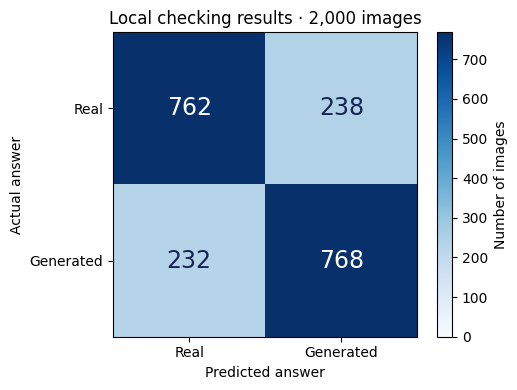

Real: 762/1000 correctly identified (76.2%)
Generated: 768/1000 correctly identified (76.8%)


In [10]:
confusion = torch.tensor(holdout_metrics['confusion_matrix'])
names = ['Real', 'Generated']
fig, ax = plt.subplots(figsize=(5.2, 4))
image = ax.imshow(confusion, cmap='Blues', vmin=0)
ax.set(xticks=range(2), yticks=range(2), xticklabels=names, yticklabels=names,
       xlabel='Predicted answer', ylabel='Actual answer', title='Local checking results · 2,000 images')
for row in range(2):
    for column in range(2):
        value = confusion[row, column].item()
        ax.text(column, row, str(value), ha='center', va='center', fontsize=17,
                color='white' if value > confusion.max().item() / 2 else '#172554')
fig.colorbar(image, ax=ax, label='Number of images')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / '03_confusion_matrix.png', bbox_inches='tight')
plt.show()
plt.close(fig)
for index, name in enumerate(names):
    correct = confusion[index, index].item()
    total = confusion[index].sum().item()
    print(f'{name}: {correct}/{total} correctly identified ({correct / total:.1%})')

# 8. Train and save the final model

The model was trained on RGB images with a shape of `3 × 32 × 32`, converting pixel values to floating-point numbers between `0` and `1`. For a batch of images, the model returns two scores per image and I select the larger score to obtain the predicted label, where **0 means real** and **1 means generated**.

In [11]:
model, _, _, _ = fit(images, labels, chosen_epoch, settings)
weights_path = OUTPUT_DIR / 'submission_dic.pth'
torch.save(model.state_dict(), weights_path)
(OUTPUT_DIR / 'submission_model.py').write_text('from torch import nn\n\n\nclass MyModel(nn.Module):\n\n    def __init__(self):\n        super().__init__()\n        self.conv1 = nn.Conv2d(3, 32, 3, padding=1)\n        self.relu1 = nn.ReLU()\n        self.pool1 = nn.MaxPool2d(2)\n        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)\n        self.relu2 = nn.ReLU()\n        self.pool2 = nn.MaxPool2d(2)\n        self.fc1 = nn.Linear(64 * 8 * 8, 2)\n\n    def forward(self, x):\n        x = self.conv1(x)\n        x = self.relu1(x)\n        x = self.pool1(x)\n        x = self.conv2(x)\n        x = self.relu2(x)\n        x = self.pool2(x)\n        x = x.flatten(1)\n        x = self.fc1(x)\n        return x\n', encoding='utf-8')

Epoch 1/35: training loss=0.593792
Epoch 5/35: training loss=0.530218
Epoch 10/35: training loss=0.503007
Epoch 15/35: training loss=0.481269
Epoch 20/35: training loss=0.449919
Epoch 25/35: training loss=0.427284
Epoch 30/35: training loss=0.412165
Epoch 35/35: training loss=0.399541


635

In [12]:
restored_model = MyModel()
restored_model.load_state_dict(torch.load(weights_path, map_location='cpu', weights_only=True))
restored_model.eval()
with torch.no_grad():
    scores = restored_model(images[:4])
print('Example scores [real, generated]:')
print(scores)
print('Predicted labels:', scores.argmax(dim=1).tolist())
print('Actual labels:   ', labels[:4].tolist())
print('These four images were used for final training; this is a loading demonstration.')


Example scores [real, generated]:
tensor([[ 1.0504, -1.0707],
        [ 0.9036, -0.7553],
        [ 0.4724, -0.3352],
        [ 0.2175, -0.1182]])
Predicted labels: [0, 0, 0, 0]
Actual labels:    [0, 0, 0, 0]
These four images were used for final training; this is a loading demonstration.


In [13]:
cm = torch.tensor(holdout_metrics['confusion_matrix'])
real_total = int(cm[0].sum())
generated_total = int(cm[1].sum())

# Reuse the baseline evaluated earlier in the notebook.
baseline_accuracy = baseline
improvement = 100 * (
    holdout_metrics['accuracy'] - baseline_accuracy
)

In [14]:
elapsed_seconds = perf_counter() - NOTEBOOK_START
print(
    f'Measured notebook runtime for this run: '
    f'{elapsed_seconds:.2f} seconds'
)

Measured notebook runtime for this run: 330.08 seconds


# Conclusion

I evaluated the convolutional neural network on **2,000 local holdout images** where it correctly classified **1,530 images** and achieved a whopping **76.50% accuracy**. Compared with the majority-class baseline of **50.00%** which this is an improvement of **26.50 percentage points** equivalent to **530 additional correct predictions**.

| Actual image type | Correct predictions | Incorrect predictions | Accuracy |
| --- | ---: | ---: | ---: |
| Real | 762 | 238 | 76.20% |
| Generated | 768 | 232 | 76.80% |

The model performed similarly on both categories, although it misclassified slightly more real images than generated images in this run. These results describe its performance on the supplied dataset and this particular split while its performance on other image generators or image collections remains untested.

After evaluating the selected recipe, I trained a fresh final model using all **10,000 supplied labeled images** and saved its weights together with the matching model definition.